JS01 Tugas Praktikum 1.

Bagian 1 - audit 4 library yang diminta modul (PyPREP, SciPy, wandb, pyECG):
           status import + versi + kegunaan, plus demo scipy nyata sebagai
           pengganti pyECG (deteksi R-peak sinyal EKG sintetis).
Bagian 2 - jawaban etika & dampak lingkungan (ditulis ke output/*.md).

Output: output/tugas1_library.csv, output/tugas1_jawaban.md,
        output/02_ecg_rpeak_scipy.png

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("tugas_praktikum_1.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js01-pengenalan-pembelajaran-mesin\tugas


In [2]:
import importlib
import platform
import sys
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from scipy import stats

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(42)

In [3]:
# ---------------------------------------------------------------- Bagian 1 ---
LIB = [
    ("PyPREP", "pyprep",
     "Preprocessing EEG otomatis (implementasi PREP): deteksi kanal buruk, "
     "filter line-noise, interpolasi kanal rusak, rujukan (reference). "
     "Dipakai sebelum analisis/klasifikasi sinyal EEG."),
    ("SciPy", "scipy",
     "Komputasi ilmiah: aljabar linear, optimasi, interpolasi, statistika "
     "(scipy.stats), pengolahan sinyal (scipy.signal), integrasi. Fondasi "
     "banyak library ML."),
    ("wandb", "wandb",
     "Weights & Biases: pencatatan eksperimen (metrik per epoch, kurva, "
     "artefak model), pembandingan run, dan pelaporan hasil secara daring."),
    ("pyECG", "pyecg",
     "Pengolahan sinyal EKG: pembacaan format rekaman (WFDB/ISHNE Holter), "
     "deteksi gelombang (P-QRS-T), ekstraksi fitur denyut."),
]

print("=" * 70)
print("JS01 / Tugas Praktikum 1 - Bagian 1: audit library")
print("=" * 70)
print(f"python {sys.version.split()[0]} | {platform.platform()}\n")

rows = []
for nama, mod_name, kegunaan in LIB:
    try:
        mod = importlib.import_module(mod_name)
        ver = getattr(mod, "__version__", "?")
        status = "TERPASANG"
    except Exception as exc:  # noqa: BLE001
        ver, status = "-", f"TIDAK ADA ({type(exc).__name__})"
    rows.append((nama, mod_name, ver, status, kegunaan))
    print(f"{nama:<8} {status:<22} versi={ver:<10} {kegunaan[:60]}...")

ada = sum(1 for r in rows if r[3] == "TERPASANG")
print(f"\nterpasang: {ada}/{len(rows)}")

import csv

with (OUT / "tugas1_library.csv").open("w", newline="", encoding="utf-8") as fh:
    wr = csv.writer(fh)
    wr.writerow(["library", "modul_python", "versi", "status", "kegunaan"])
    wr.writerows(rows)

JS01 / Tugas Praktikum 1 - Bagian 1: audit library
python 3.10.6 | Windows-10-10.0.26200-SP0

PyPREP   TIDAK ADA (ModuleNotFoundError) versi=-          Preprocessing EEG otomatis (implementasi PREP): deteksi kana...
SciPy    TERPASANG              versi=1.15.3     Komputasi ilmiah: aljabar linear, optimasi, interpolasi, sta...
wandb    TIDAK ADA (ModuleNotFoundError) versi=-          Weights & Biases: pencatatan eksperimen (metrik per epoch, k...
pyECG    TIDAK ADA (ModuleNotFoundError) versi=-          Pengolahan sinyal EKG: pembacaan format rekaman (WFDB/ISHNE ...

terpasang: 1/4


In [4]:
# --- demo SciPy: uji-t dua sampel -------------------------------------------
print("\n[a] Demo scipy.stats: uji-t tinggi badan dua kelompok (data sintetis)")
tinggi_a = RNG.normal(165, 6, 30)
tinggi_b = RNG.normal(170, 6, 30)
t_stat, p_val = stats.ttest_ind(tinggi_a, tinggi_b)
print(f"  mean A={tinggi_a.mean():.2f} cm, mean B={tinggi_b.mean():.2f} cm")
print(f"  t={t_stat:.4f}, p={p_val:.3e} -> "
      f"{'beda signifikan' if p_val < 0.05 else 'tidak beda signifikan'} (alpha=0.05)")


[a] Demo scipy.stats: uji-t tinggi badan dua kelompok (data sintetis)
  mean A=165.10 cm, mean B=170.68 cm
  t=-4.5557, p=2.735e-05 -> beda signifikan (alpha=0.05)



[b] Demo scipy.signal: deteksi R-peak EKG sintetis (fungsi inti pyECG)
  durasi=10s fs=250Hz, jumlah denyut terdeteksi=12
  RR rata-rata=833.5 ms (std 1.9 ms), HR=72.0 bpm
  HR ground-truth=72 bpm -> galat=0.01 bpm


  grafik -> 02_ecg_rpeak_scipy.png


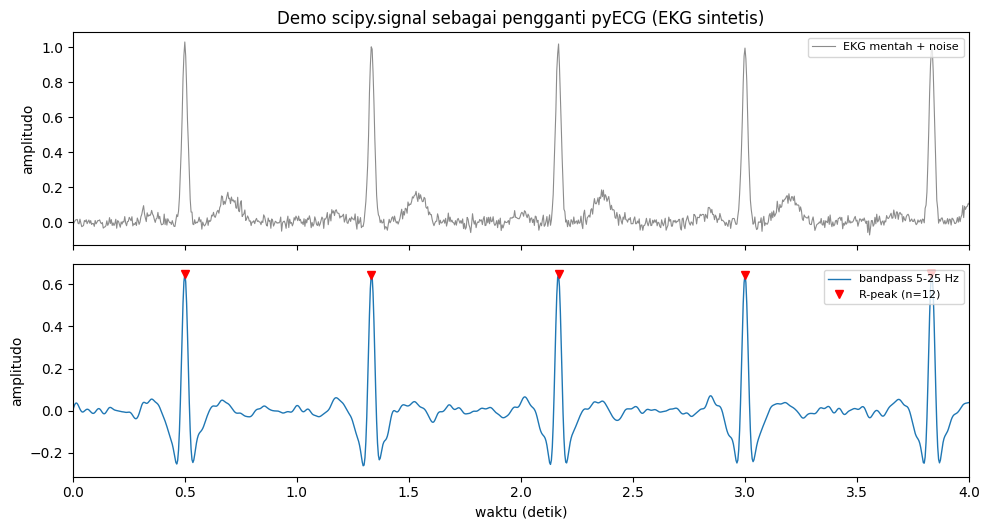

In [5]:
# --- demo SciPy pengganti pyECG: deteksi R-peak ------------------------------
print("\n[b] Demo scipy.signal: deteksi R-peak EKG sintetis (fungsi inti pyECG)")
fs = 250.0                      # Hz
durasi = 10.0                   # detik
t = np.arange(0, durasi, 1 / fs)
bpm = 72.0
ekg = np.zeros_like(t)
for beat in np.arange(0.5, durasi, 60.0 / bpm):
    ekg += 1.0 * np.exp(-0.5 * ((t - beat) / 0.012) ** 2)          # QRS
    ekg += 0.15 * np.exp(-0.5 * ((t - beat - 0.20) / 0.040) ** 2)  # T
    ekg += 0.05 * np.exp(-0.5 * ((t - beat + 0.16) / 0.030) ** 2)  # P
ekg += RNG.normal(0, 0.02, t.size)

b, a = signal.butter(3, [5.0, 25.0], btype="bandpass", fs=fs)
ekg_f = signal.filtfilt(b, a, ekg)
jarak_min = int(0.25 * fs)
puncak, _ = signal.find_peaks(ekg_f, height=0.4, distance=jarak_min)
rr = np.diff(puncak) / fs
hr = 60.0 / rr.mean()
print(f"  durasi={durasi:.0f}s fs={fs:.0f}Hz, jumlah denyut terdeteksi={puncak.size}")
print(f"  RR rata-rata={rr.mean()*1000:.1f} ms (std {rr.std()*1000:.1f} ms), "
      f"HR={hr:.1f} bpm")
print(f"  HR ground-truth={bpm:.0f} bpm -> galat={abs(hr - bpm):.2f} bpm")

fig, ax = plt.subplots(2, 1, figsize=(10, 5.4), sharex=True)
ax[0].plot(t, ekg, color="0.55", lw=0.8, label="EKG mentah + noise")
ax[0].set_ylabel("amplitudo")
ax[0].set_title("Demo scipy.signal sebagai pengganti pyECG (EKG sintetis)")
ax[0].legend(fontsize=8, loc="upper right")
ax[1].plot(t, ekg_f, color="tab:blue", lw=1.0, label="bandpass 5-25 Hz")
ax[1].plot(t[puncak], ekg_f[puncak], "rv", ms=6, label=f"R-peak (n={puncak.size})")
ax[1].set_xlabel("waktu (detik)")
ax[1].set_ylabel("amplitudo")
ax[1].legend(fontsize=8, loc="upper right")
ax[1].set_xlim(0, 4)
fig.tight_layout()
fig.savefig(OUT / "02_ecg_rpeak_scipy.png", dpi=130)
print(f"  grafik -> {(OUT / '02_ecg_rpeak_scipy.png').name}")

In [6]:
# ---------------------------------------------------------------- Bagian 2 ---
JAWABAN = f"""# Tugas Praktikum 1 - Jawaban## Bagian 1 - Library

| Library | Status di venv ini | Kegunaan |
|---|---|---|
| PyPREP | {rows[0][3]} | {rows[0][4]} |
| SciPy | {rows[1][3]} (v{rows[1][2]}) | {rows[1][4]} |
| wandb | {rows[2][3]} | {rows[2][4]} |
| pyECG | {rows[3][3]} | {rows[3][4]} |

Cara instalasi (sesuai modul, dijalankan di Colab/lokal):

```
pip install pyprep scipy wandb pyecg
```

Catatan eksekusi nyata: `pyprep` dan `wandb` dapat di-resolve oleh pip pada
venv ini (dry-run berhasil, PyPREP menarik `mne>=1.3`), tetapi tidak dipasang
karena venv dipakai bersama proses lain dan penambahan `mne` berisiko
menggeser pin numpy/scipy. `pyecg` GAGAL di-resolve: dependensinya
`ishneholterlib==2017.4.11 -> sklearn` (paket shim lama) yang harus dibangun
dari source dan butuh MSVC (tidak tersedia di mesin ini). Karena itu fungsi
inti pyECG (baca sinyal EKG + deteksi QRS) didemonstrasikan ulang memakai
`scipy.signal` di script ini.## Bagian 2.1 - Contoh pelanggaran etika dan hukum AI

**Kasus: pengumpulan wajah massal tanpa persetujuan (Clearview AI).**
Clearview AI mengambil miliaran foto wajah dari internet dan media sosial
tanpa izin untuk membangun basis data pengenalan wajah yang dijual ke penegak
hukum dan swasta. Otoritas perlindungan data di Italia (Garante), Prancis
(CNIL), dan Inggris (ICO) menjatuhkan denda serta memerintahkan penghapusan
data karena melanggar GDPR/prinsip pemrosesan yang sah, dan sejumlah lembaga
lain menyimpulkan praktik ini melanggar privasi.

Pelanggaran yang terjadi:
1. **Privacy** - data biometrik dipanen tanpa dasar hukum dan tanpa
   persetujuan subjek.
2. **Transparency & accountability** - subjek data tidak tahu wajahnya dipakai
   dan tidak punya mekanisme koreksi.
3. **Fairness** - akurasi pengenalan wajah lebih rendah pada kelompok tertentu
   (kulit gelap, perempuan), sehingga risiko salah tuduh tidak merata.

Contoh lain yang sering dirujuk: skandal tunjangan anak di Belanda
(*toeslagenaffaire*) - sistem klasifikasi risiko yang bias etnis/kelas
menyebabkan ribuan keluarga dituduh curang secara keliru, dan sistem skor
kredit yang menolak pinjaman berdasarkan atribut proksi (kode pos, jenis
perangkat) alih-alih kemampuan bayar.

Referensi:
- Microsoft, *Responsible AI - Principles and Approach*,
  https://www.microsoft.com/en-us/ai/principles-and-approach
- Garante per la protezione dei dati personali (2022), provvedimento su
  Clearview AI, https://www.garanteprivacy.it
- CNIL (2022), sanction Clearview AI, https://www.cnil.fr
- ICO (2022), enforcement notice Clearview AI, https://ico.org.uk
- Autoriteit Persoonsgegevens (2021), boete toeslagenaffaire,
  https://www.autoriteitpersoonsgegevens.nl## Bagian 2.2 - Dampak energi & lingkungan dan cara mengatasinya

Dampak yang nyata:
1. **Fase fabrikasi** - produksi chip akselerator (GPU/TPU/HBM) memakai
   energi, air ultramurni, dan bahan kimia per unit yang jauh lebih besar
   daripada chip biasa; jejak karbonnya "dibayar di muka" sebelum model
   dipakai.
2. **Fase pelatihan** - pra-pelatihan model besar butuh ribuan GPU-jam.
   Strubell dkk. (2019) menunjukkan biaya energi/emisi pelatihan model NLP
   dapat menyamai emisi beberapa kali penerbangan lintas benua, dan biaya itu
   berlipat saat tuning hiperparameter tanpa pelaporan.
3. **Fase inferensi** - biaya terbesar jangka panjang karena berjalan terus
   menerus; layanan GenAI menambah beban listrik dan air pendingin pusat
   data. Laporan IEA *Energy and AI* (2025) memproyeksikan konsumsi listrik
   pusat data melonjak terutama karena akselerator AI.
4. **Efek ikutan** - rebutan air tanah di daerah kering, limbah e-waste
   akselerator, dan naiknya harga listrik lokal di sekitar pusat data.

Cara mengatasi (pendapat pribadi, dari yang termurah):
1. **Jangan latih kalau tidak perlu** - pakai model kecil/fine-tuning/distilasi
   atau API yang sudah ada; sebagian besar kebutuhan kampus/industri kecil
   selesai dengan model < 1B parameter.
2. **Kurangi beban inferensi** - kuantisasi (int8/4-bit), pruning, caching,
   batching, dan routing ke model kecil untuk query mudah.
3. **Ukur dan laporkan** - catat energi/emisi per eksperimen (mis. wandb +
   CodeCarbon), jadikan metrik seperti akurasi. Yang tidak diukur tidak
   dikurangi; ini juga alasan wandb relevan di praktikum.
4. **Pemilihan waktu & lokasi** - penjadwalan job ke jam/region dengan
   intensitas karbon listrik rendah, serta PPA energi terbarukan.
5. **Pendinginan & air** - pendingin cair tertutup/immersion dan daur ulang
   air, bukan sekali pakai.
6. **Umur pakai & daur ulang** - perpanjang masa pakai akselerator, tuntut
   desain yang bisa diperbaiki, dan kelola e-waste resmi.
7. **Regulasi & transparansi** - kewajiban pelaporan konsumsi energi model
   besar, seperti arah EU AI Act terhadap model tujuan umum.

Referensi:
- IEA (2025), *Energy and AI*, https://www.iea.org/reports/energy-and-ai
- Strubell, Ganesh & McCallum (2019), *Energy and Policy Considerations for
  Deep Learning in NLP*, ACL 2019, https://aclanthology.org/P19-1355/
- Bender, Gebru, McMillan-Major & Shmitchell (2021), *On the Dangers of
  Stochastic Parrots*, FAccT 2021, https://doi.org/10.1145/3442188.3445922
- Schwartz dkk. (2020), *Green AI*, Communications of the ACM,
  https://doi.org/10.1145/3386890
- Microsoft, *Responsible AI - Principles and Approach* (prinsip
  reliability/safety & accountability),
  https://www.microsoft.com/en-us/ai/principles-and-approach
"""
(OUT / "tugas1_jawaban.md").write_text(JAWABAN, encoding="utf-8")
print(f"\n[c] jawaban Bagian 1+2 -> {(OUT / 'tugas1_jawaban.md').name}")
print(f"    panjang jawaban: {len(JAWABAN.splitlines())} baris")

assert ekg.size == t.size
assert abs(hr - bpm) < 5, f"estimasi HR meleset: {hr:.1f} vs {bpm}"
assert p_val < 0.05
assert (OUT / "tugas1_jawaban.md").stat().st_size > 3000
print("\nSELESAI: Bagian 1 (audit+2 demo scipy) dan Bagian 2 (etika+lingkungan) siap.")


[c] jawaban Bagian 1+2 -> tugas1_jawaban.md
    panjang jawaban: 101 baris

SELESAI: Bagian 1 (audit+2 demo scipy) dan Bagian 2 (etika+lingkungan) siap.
